# California Housing: OLS vs Ridge vs Lasso Regression

**Goal:** Predict `median_house_value` and compare Ordinary Least Squares (OLS), Ridge (L2) and Lasso (L1) regression using RMSE, MAE and R².

**Pipeline**
1. Load data and inspect missing values
2. Correlation heatmap
3. Engineer ratio and interaction features
4. Detect and reduce multicollinearity (VIF)
5. Train/test split, then impute, scale and encode inside a `Pipeline` (no data leakage)
6. Tune Ridge and Lasso `alpha` with `GridSearchCV`
7. Compare models; plot predicted vs actual and residual distributions

## 1. Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

## 2. Load the dataset and handle missing values

In [2]:
df = pd.read_csv("california_housing.csv")   # keep california_housing.csv in the same folder as this notebook
print("Shape:", df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'california_housing.csv'

In [ ]:
print(df.dtypes, "\n")
missing = df.isna().sum()
print("Missing values:\n", missing[missing > 0])
print(f"\n{df['total_bedrooms'].isna().mean():.2%} of total_bedrooms is missing")
print("\nocean_proximity categories:\n", df["ocean_proximity"].value_counts())
df.describe().T.round(2)

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object 

Missing values:
 total_bedrooms    207
dtype: int64

1.00% of total_bedrooms is missing

ocean_proximity categories:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


**Missing values:** only `total_bedrooms` has nulls (207 rows). They are imputed with the **median** (robust to the strong right skew in this column). The imputer is fitted on the training set only, inside the pipeline.

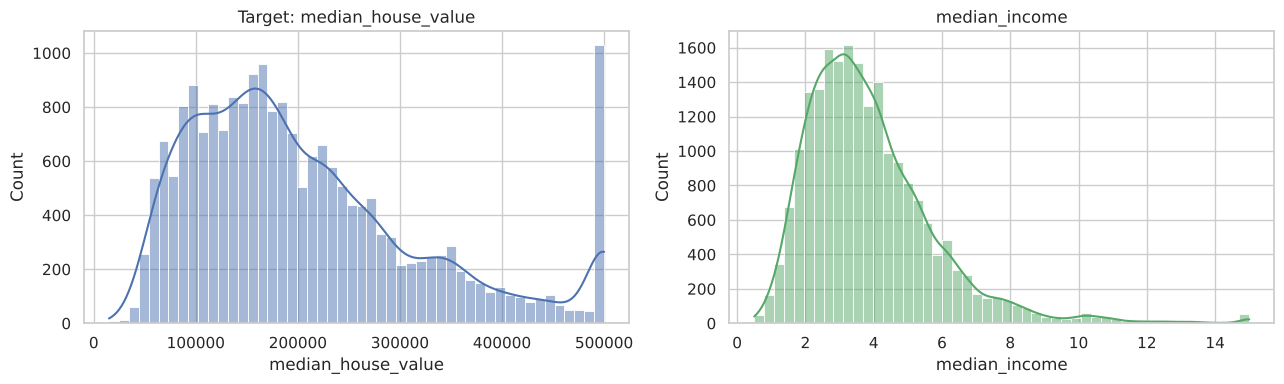

Rows at the $500,001 price cap: 992


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=50, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Target: median_house_value")
sns.histplot(df["median_income"], bins=50, kde=True, ax=axes[1], color="#55a868")
axes[1].set_title("median_income")
plt.tight_layout(); plt.show()

print("Rows at the $500,001 price cap:", (df["median_house_value"] >= 500000).sum())

The target is **capped at $500,001** (992 districts). This ceiling limits how well any linear model can fit the top end, and it will show up in the residual plots later.

## 3. Correlation heatmap

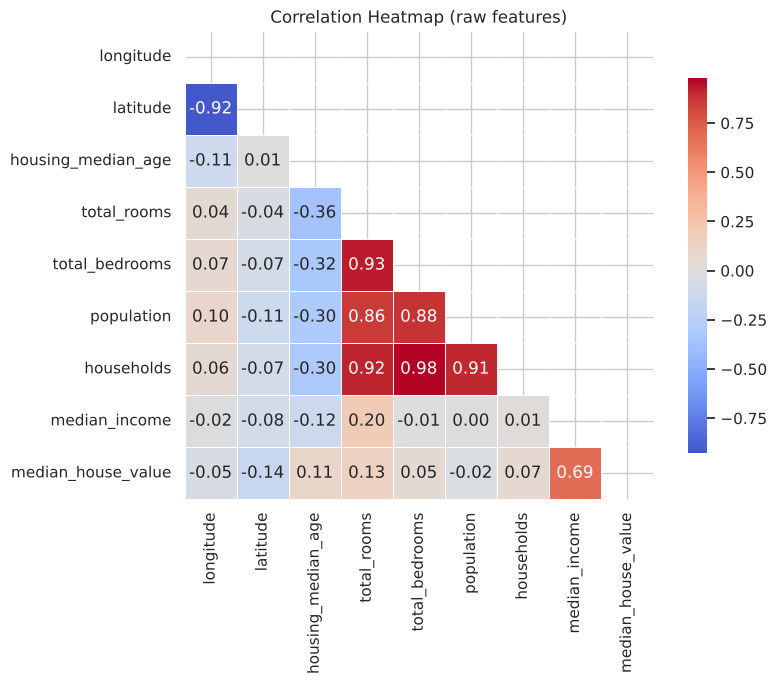

median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [ ]:
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap (raw features)")
plt.tight_layout(); plt.show()

print(corr["median_house_value"].drop("median_house_value").sort_values(ascending=False).round(3))

**Observations**
- `median_income` is by far the strongest predictor of house value.
- `total_rooms`, `total_bedrooms`, `population` and `households` are very strongly correlated with each other (about 0.9 or higher). That is **multicollinearity**, handled in section 5.
- `latitude` and `longitude` are almost perfectly negatively correlated because California runs diagonally.

## 4. Feature engineering

Raw counts like `total_rooms` depend on district size, so per-household ratios are more meaningful. Interaction terms let the model capture effects that only appear when two features combine.

| Feature | Meaning |
|---|---|
| `rooms_per_household` | Average rooms per household |
| `bedrooms_per_room` | Share of rooms that are bedrooms |
| `population_per_household` | Average household size |
| `income_x_rooms_per_hh` | Interaction: income × rooms per household |
| `income_x_age` | Interaction: income × housing age |
| `lat_x_lon` | Interaction: lets the model capture the diagonal coastline |

In [ ]:
def add_features(data):
    d = data.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]      # stays NaN where bedrooms is missing
    d["population_per_household"] = d["population"] / d["households"]
    d["income_x_rooms_per_hh"] = d["median_income"] * d["rooms_per_household"]
    d["income_x_age"] = d["median_income"] * d["housing_median_age"]
    d["lat_x_lon"] = d["latitude"] * d["longitude"]
    return d

df_fe = add_features(df)
df_fe[["rooms_per_household", "bedrooms_per_room", "population_per_household",
       "income_x_rooms_per_hh", "income_x_age", "lat_x_lon"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
bedrooms_per_room,20433.0,0.21,0.06,0.10,0.18,0.20,0.24,1.00
population_per_household,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
income_x_rooms_per_hh,20640.0,22.55,17.92,0.86,11.69,18.02,27.86,612.97
income_x_age,20640.0,108.01,74.39,1.62,58.00,92.50,140.10,780.01
lat_x_lon,20640.0,-4264.45,323.90,-5207.67,-4601.03,-4060.28,-4004.35,-3753.97


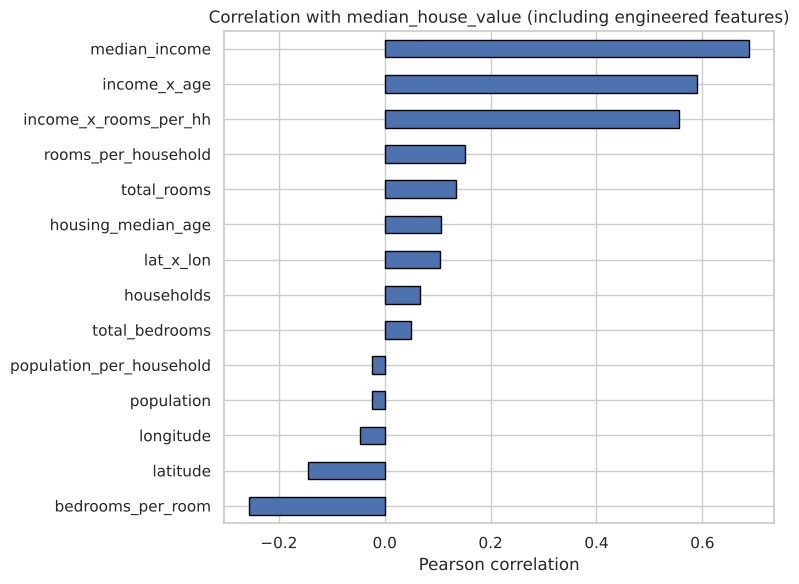

In [ ]:
# Row-wise ratios do not use information from other rows, so computing them before the split causes no leakage.
corr2 = df_fe.select_dtypes(include="number").corr()["median_house_value"].drop("median_house_value")
corr2.sort_values().plot(kind="barh", figsize=(8, 6), color="#4c72b0", edgecolor="black")
plt.title("Correlation with median_house_value (including engineered features)")
plt.xlabel("Pearson correlation"); plt.tight_layout(); plt.show()

## 5. Multicollinearity: Variance Inflation Factor (VIF)

VIF measures how well each feature can be predicted from all the others. **VIF above 10** is a common warning level for serious multicollinearity. It is computed here from the inverse of the correlation matrix (equivalent to the regression-based definition).

In [ ]:
def compute_vif(frame):
    x = frame.dropna()
    inv = np.linalg.inv(x.corr().values)
    return pd.Series(np.diag(inv), index=x.columns, name="VIF").sort_values(ascending=False)

all_num = [c for c in df_fe.select_dtypes(include="number").columns if c != "median_house_value"]
vif_before = compute_vif(df_fe[all_num])
vif_before.round(1)

lat_x_lon                   13322.5
latitude                     8389.2
longitude                     653.1
total_bedrooms                 49.9
households                     44.6
median_income                  20.2
total_rooms                    19.3
income_x_rooms_per_hh          18.3
income_x_age                    9.3
population                      6.9
rooms_per_household             5.5
housing_median_age              5.5
bedrooms_per_room               2.9
population_per_household        1.1
Name: VIF, dtype: float64

Many features exceed the threshold: `lat_x_lon` (VIF in the thousands), `latitude`, `longitude`, the raw count columns (`total_bedrooms`, `households`, `total_rooms`), and the uncentred interaction `income_x_rooms_per_hh` along with `median_income`, which it is built from. Fixes applied: the raw counts are replaced by the ratio features, `lat_x_lon` is dropped, and the interaction terms are **mean-centred** before multiplying, the standard way to remove collinearity between a product term and its parent features.

In [ ]:
# Centre the components of the interaction features, then rebuild them
def add_features_v2(data):
    d = data.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    d["population_per_household"] = d["population"] / d["households"]
    return d

df_fe2 = add_features_v2(df)
# Centring constants come from the whole frame only for the VIF diagnostic below;
# the model pipeline recomputes them from the training split (see section 6).
inc_c = df_fe2["median_income"] - df_fe2["median_income"].mean()
age_c = df_fe2["housing_median_age"] - df_fe2["housing_median_age"].mean()
rooms_c = df_fe2["rooms_per_household"] - df_fe2["rooms_per_household"].mean()
df_fe2["income_x_rooms_per_hh"] = inc_c * rooms_c
df_fe2["income_x_age"] = inc_c * age_c

reduced = ["longitude", "latitude", "housing_median_age", "median_income",
           "rooms_per_household", "bedrooms_per_room", "population_per_household",
           "income_x_rooms_per_hh", "income_x_age"]
vif_after = compute_vif(df_fe2[reduced])

vif_cmp = pd.concat([vif_before.rename("VIF before"), vif_after.rename("VIF after")], axis=1)
print(vif_cmp.round(1).to_string())

                          VIF before  VIF after
lat_x_lon                    13322.5        NaN
latitude                      8389.2        9.4
longitude                      653.1        9.1
total_bedrooms                  49.9        NaN
households                      44.6        NaN
median_income                   20.2        2.7
total_rooms                     19.3        NaN
income_x_rooms_per_hh           18.3        1.4
income_x_age                     9.3        1.0
population                       6.9        NaN
rooms_per_household              5.5        1.4
housing_median_age               5.5        1.1
bedrooms_per_room                2.9        2.0
population_per_household         1.1        1.0


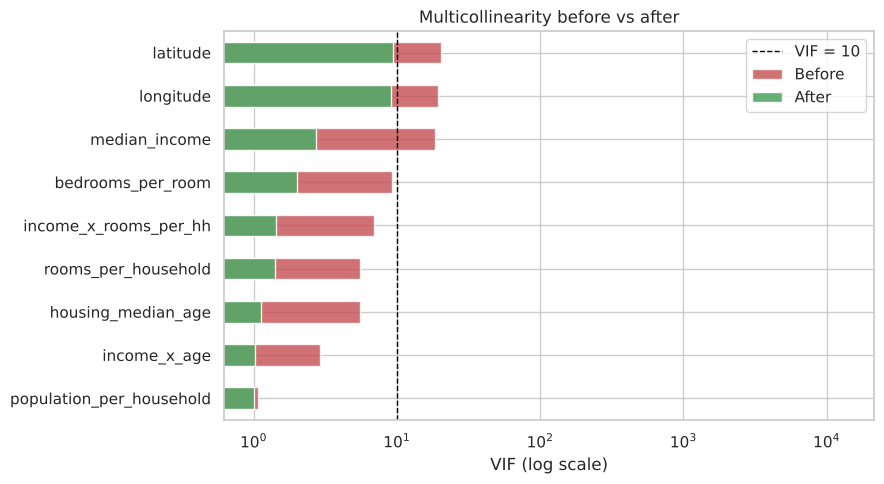

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
vif_before.sort_values().plot(kind="barh", ax=ax, color="#c44e52", alpha=0.8, label="Before")
vif_after.reindex(vif_before.index).dropna().sort_values().plot(kind="barh", ax=ax, color="#55a868", label="After", alpha=0.9)
ax.axvline(10, color="black", ls="--", lw=1, label="VIF = 10")
ax.set_xscale("log"); ax.set_xlabel("VIF (log scale)"); ax.set_title("Multicollinearity before vs after")
ax.legend(); plt.tight_layout(); plt.show()

After these fixes every feature is below the threshold of 10. `longitude` and `latitude` (VIF about 9) remain the most correlated pair. They carry the location signal together, so both are kept, and Ridge and Lasso are designed to handle exactly this kind of leftover correlation.

## 6. Train/test split and preprocessing pipeline

Split **first (80/20)**, then fit every data-dependent step (imputer, centring, scaler, encoder) on the **training set only**. A custom transformer builds the engineered features inside the pipeline so cross-validation stays leak-free.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Adds ratio features and mean-centred interaction terms. Means are learned on the training fold only."""
    def fit(self, X, y=None):
        X = self._ratios(X)
        self.income_mean_ = X["median_income"].mean()
        self.age_mean_ = X["housing_median_age"].mean()
        self.rooms_mean_ = X["rooms_per_household"].mean()   # NaN-safe: pandas skips NaN
        return self

    def _ratios(self, X):
        X = X.copy()
        X["rooms_per_household"] = X["total_rooms"] / X["households"]
        X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"]
        X["population_per_household"] = X["population"] / X["households"]
        return X

    def transform(self, X):
        X = self._ratios(X)
        inc = X["median_income"] - self.income_mean_
        age = X["housing_median_age"] - self.age_mean_
        rooms = X["rooms_per_household"] - self.rooms_mean_
        X["income_x_rooms_per_hh"] = inc * rooms
        X["income_x_age"] = inc * age
        return X.drop(columns=["total_rooms", "total_bedrooms", "population", "households"])

TARGET = "median_house_value"
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

num_features = ["longitude", "latitude", "housing_median_age", "median_income",
                "rooms_per_household", "bedrooms_per_room", "population_per_household",
                "income_x_rooms_per_hh", "income_x_age"]
cat_features = ["ocean_proximity"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_features),
])

def make_pipeline(model):
    return Pipeline([("features", FeatureBuilder()), ("prep", preprocess), ("model", model)])

Train: 16512 rows | Test: 4128 rows


**Encoding note:** `drop="first"` removes one dummy column per category. Without it the one-hot columns always sum to 1, which creates perfect multicollinearity and makes OLS unstable.

## 7. Train OLS and tune Ridge and Lasso with GridSearchCV

In [ ]:
# OLS baseline
ols = make_pipeline(LinearRegression()).fit(X_train, y_train)

# Ridge: search alpha on a log grid with 5-fold CV
ridge_grid = GridSearchCV(
    make_pipeline(Ridge(random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-3, 4, 29)},
    scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, return_train_score=True)
ridge_grid.fit(X_train, y_train)

# Lasso: same idea (max_iter raised so the solver converges)
lasso_grid = GridSearchCV(
    make_pipeline(Lasso(max_iter=50000, random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-2, 4, 25)},
    scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, return_train_score=True)
lasso_grid.fit(X_train, y_train)

print(f"Best Ridge alpha : {ridge_grid.best_params_['model__alpha']:.3f} | CV RMSE = {-ridge_grid.best_score_:,.0f}")
print(f"Best Lasso alpha : {lasso_grid.best_params_['model__alpha']:.3f} | CV RMSE = {-lasso_grid.best_score_:,.0f}")

Best Ridge alpha : 0.562 | CV RMSE = 70,272
Best Lasso alpha : 0.562 | CV RMSE = 70,273


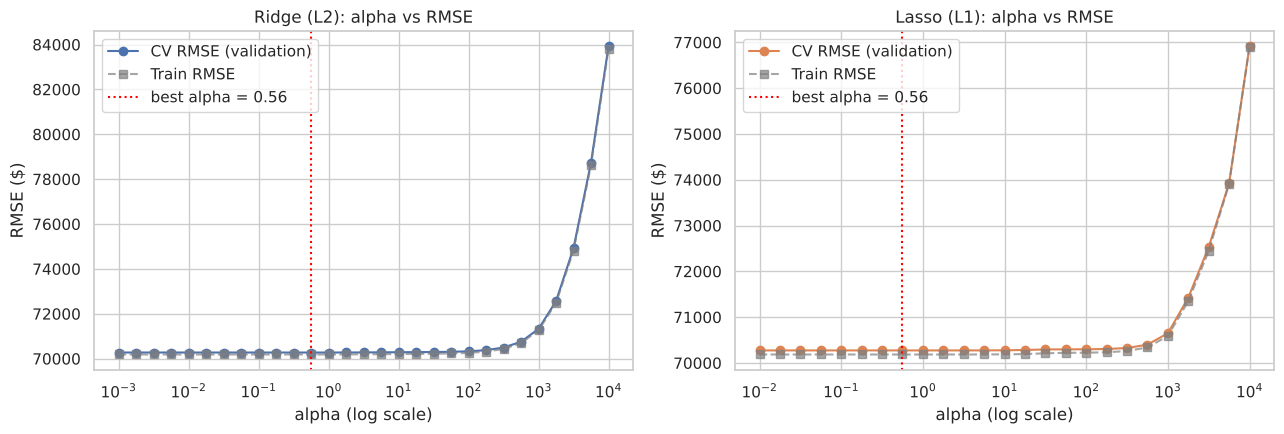

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, grid, name, col in [(axes[0], ridge_grid, "Ridge (L2)", "#4c72b0"),
                            (axes[1], lasso_grid, "Lasso (L1)", "#dd8452")]:
    r = grid.cv_results_
    alphas = r["param_model__alpha"].data.astype(float)
    ax.semilogx(alphas, -r["mean_test_score"], "o-", color=col, label="CV RMSE (validation)")
    ax.semilogx(alphas, -r["mean_train_score"], "s--", color="gray", alpha=0.7, label="Train RMSE")
    best = grid.best_params_["model__alpha"]
    ax.axvline(best, color="red", ls=":", label=f"best alpha = {best:.2f}")
    ax.set_title(f"{name}: alpha vs RMSE"); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("RMSE ($)")
    ax.legend()
plt.tight_layout(); plt.show()

## 8. Model comparison: RMSE, MAE, R²

In [ ]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_
models = {"OLS": ols, "Ridge (L2)": best_ridge, "Lasso (L1)": best_lasso}

def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

rows = []
for name, m in models.items():
    te = metrics(y_test, m.predict(X_test))
    tr = metrics(y_train, m.predict(X_train))
    rows.append({"Model": name, "Test RMSE": te["RMSE"], "Test MAE": te["MAE"], "Test R2": te["R2"],
                 "Train RMSE": tr["RMSE"], "Train R2": tr["R2"]})
results = pd.DataFrame(rows).set_index("Model")
results.style.format({"Test RMSE": "${:,.0f}", "Test MAE": "${:,.0f}", "Test R2": "{:.4f}",
                      "Train RMSE": "${:,.0f}", "Train R2": "{:.4f}"})

,Test RMSE,Test MAE,Test R2,Train RMSE,Train R2
Model,,,,,
OLS,"$71,558","$51,255",0.6092,"$70,193",0.6314
Ridge (L2),"$71,563","$51,260",0.6092,"$70,194",0.6314
Lasso (L1),"$71,558","$51,255",0.6092,"$70,193",0.6314


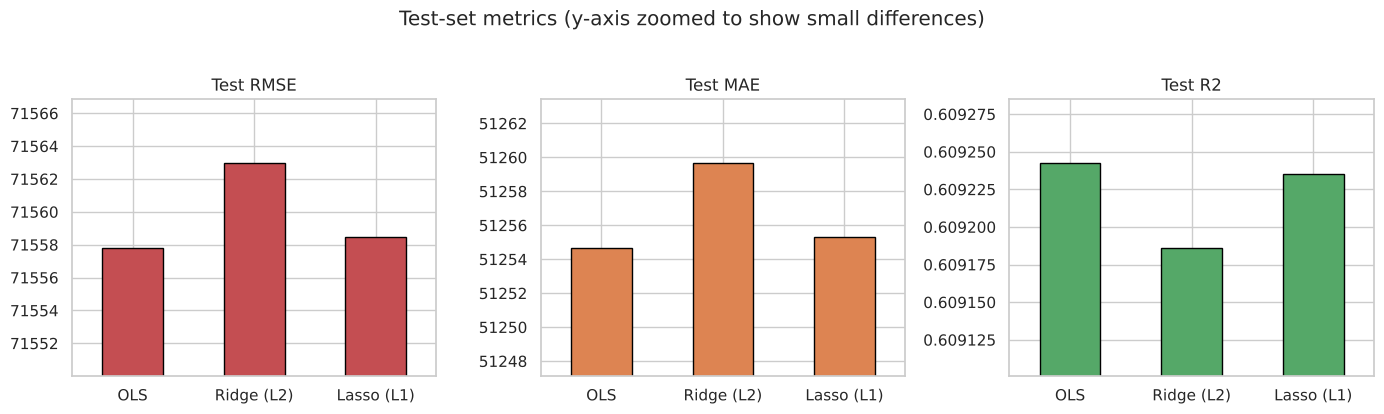

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, col in zip(axes, ["Test RMSE", "Test MAE", "Test R2"], ["#c44e52", "#dd8452", "#55a868"]):
    results[metric].plot(kind="bar", ax=ax, color=col, edgecolor="black")
    ax.set_title(metric); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    lo, hi = results[metric].min(), results[metric].max()
    pad = (hi - lo) * 1.5 + 1e-9
    ax.set_ylim(lo - pad, hi + pad * 0.5)
plt.suptitle("Test-set metrics (y-axis zoomed to show small differences)", y=1.03)
plt.tight_layout(); plt.show()

## 9. Predicted vs actual

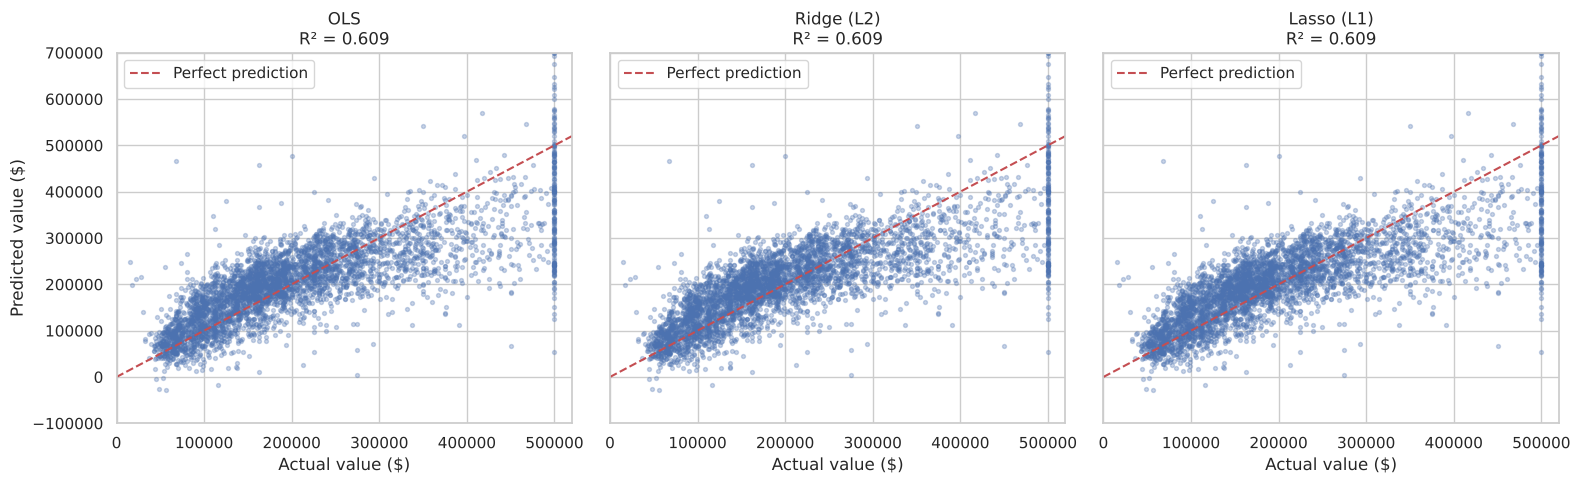

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lim = [0, 520000]
for ax, (name, m) in zip(axes, models.items()):
    pred = m.predict(X_test)
    ax.scatter(y_test, pred, s=8, alpha=0.3, color="#4c72b0")
    ax.plot(lim, lim, "r--", lw=1.5, label="Perfect prediction")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual value ($)")
    ax.set_xlim(lim); ax.set_ylim(-100000, 700000); ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted value ($)")
plt.tight_layout(); plt.show()

The vertical stripe at $500,000 is the price cap: those districts are all recorded at the same value, so the model under-predicts them. Linear models can also predict negative prices at the low end.

## 10. Residual distributions

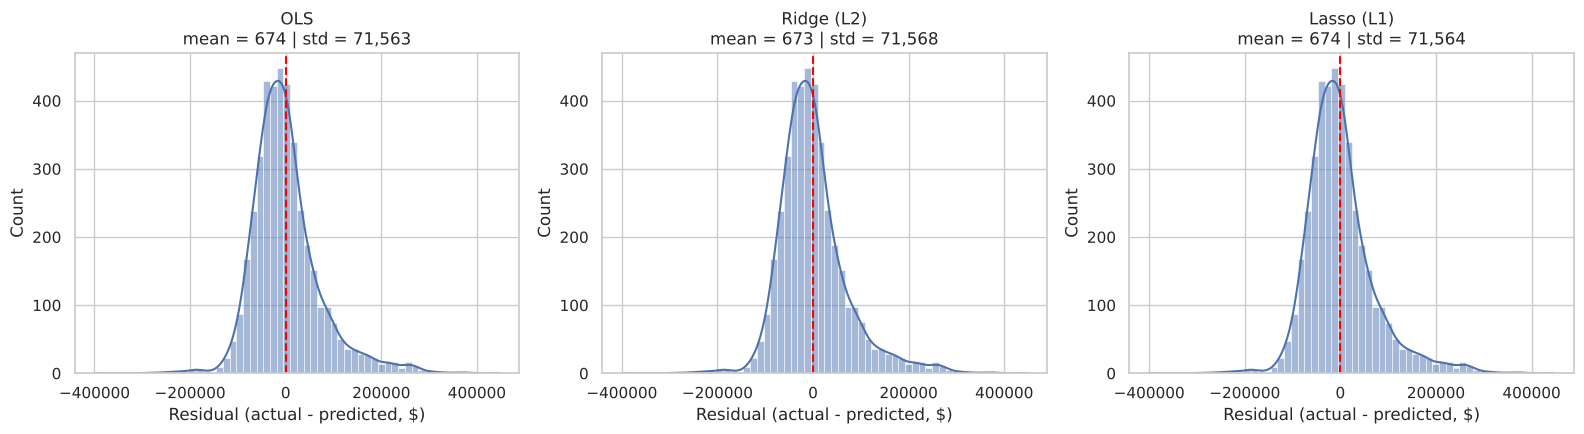

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, (name, m) in zip(axes, models.items()):
    resid = y_test - m.predict(X_test)
    sns.histplot(resid, bins=60, kde=True, ax=ax, color="#4c72b0")
    ax.axvline(0, color="red", ls="--")
    ax.set_title(f"{name}\nmean = {resid.mean():,.0f} | std = {resid.std():,.0f}")
    ax.set_xlabel("Residual (actual - predicted, $)")
plt.tight_layout(); plt.show()

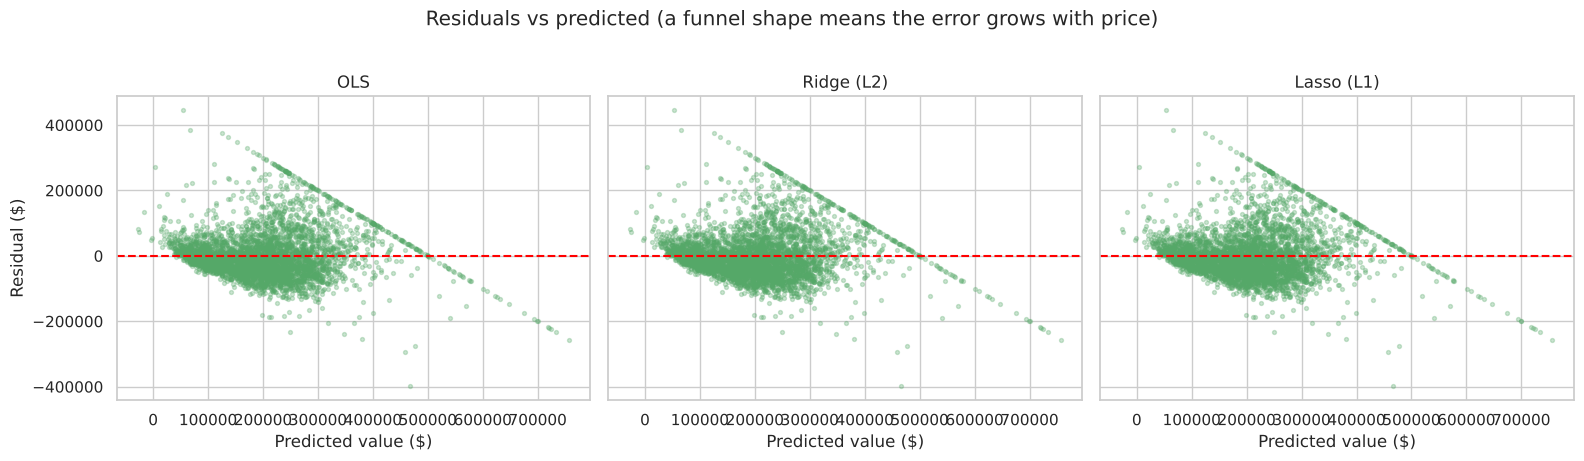

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    pred = m.predict(X_test)
    ax.scatter(pred, y_test - pred, s=8, alpha=0.3, color="#55a868")
    ax.axhline(0, color="red", ls="--")
    ax.set_title(name); ax.set_xlabel("Predicted value ($)")
axes[0].set_ylabel("Residual ($)")
plt.suptitle("Residuals vs predicted (a funnel shape means the error grows with price)", y=1.02)
plt.tight_layout(); plt.show()

## 11. What the regularisation did to the coefficients

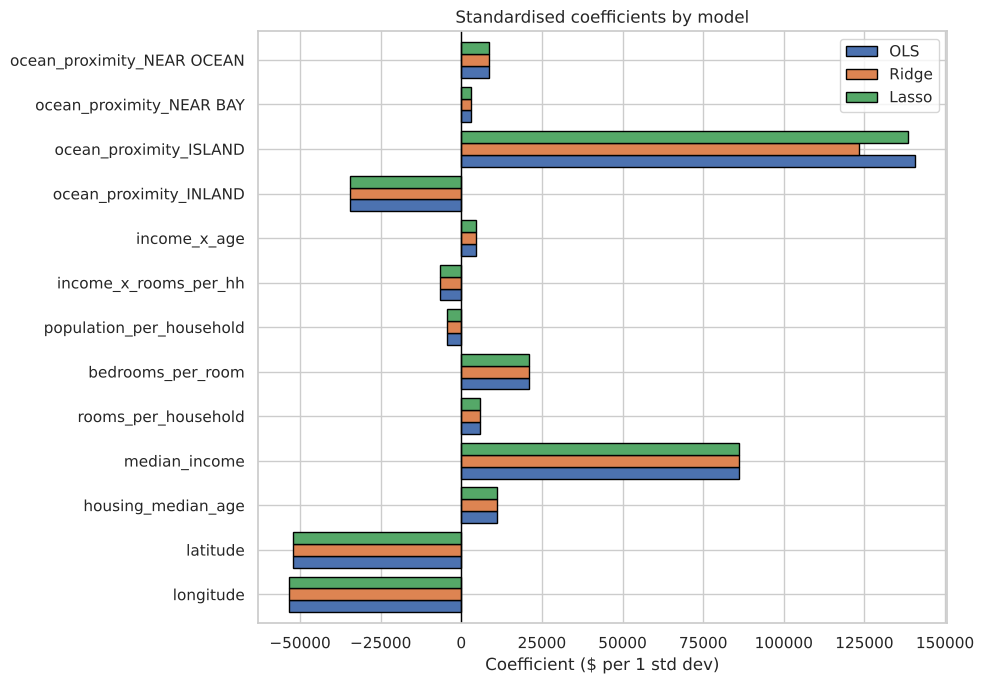

Features Lasso set exactly to zero: none (alpha is small enough to keep all features)


,OLS,Ridge,Lasso
longitude,-53339.0,-53316.0,-53331.0
latitude,-52325.0,-52305.0,-52316.0
housing_median_age,11027.0,11031.0,11028.0
median_income,86163.0,86156.0,86162.0
rooms_per_household,5769.0,5772.0,5768.0
bedrooms_per_room,21050.0,21050.0,21049.0
population_per_household,-4350.0,-4350.0,-4349.0
income_x_rooms_per_hh,-6470.0,-6467.0,-6469.0
income_x_age,4609.0,4608.0,4608.0
ocean_proximity_INLAND,-34356.0,-34373.0,-34362.0


In [ ]:
feature_names = ols.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]

coefs = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": best_ridge.named_steps["model"].coef_,
    "Lasso": best_lasso.named_steps["model"].coef_,
}, index=feature_names)

ax = coefs.plot(kind="barh", figsize=(10, 7), edgecolor="black", width=0.8)
ax.axvline(0, color="black", lw=1)
ax.set_title("Standardised coefficients by model"); ax.set_xlabel("Coefficient ($ per 1 std dev)")
plt.tight_layout(); plt.show()

zeroed = coefs.index[coefs["Lasso"].abs() < 1e-8].tolist()
print("Features Lasso set exactly to zero:", zeroed if zeroed else "none (alpha is small enough to keep all features)")
coefs.round(0)

## 12. Conclusion

- **All three models perform almost identically.** After engineering features and reducing multicollinearity, OLS has little instability left for regularisation to fix, so Ridge and Lasso offer only a marginal change. Compare the results table in section 8 to confirm.
- **Ridge (L2)** shrinks all coefficients smoothly toward zero and keeps every feature. It is the safer choice when features remain correlated.
- **Lasso (L1)** can set coefficients exactly to zero, which doubles as feature selection. Check section 11 to see whether it removed anything at the chosen alpha.
- **Linear models plateau at about R² ≈ 0.61 on this dataset.** The leftover error comes from non-linear effects (location is the main one) and the $500,000 cap, not from the choice of regulariser. Tree ensembles (Random Forest, Gradient Boosting) or a log-transformed target would be the natural next step.
- **Leakage was avoided:** the imputer, centring means, scaler and encoder are all fitted on training data only, including inside each cross-validation fold.